# P2 Notebook 3 — Transfer Learning

**Classes:** `cheetah`, `jaguar`, `leopard`, `ocelot`, `serval`

This notebook classifies the cleaned big-cat images from Notebook 2 with three pretrained Keras applications of
very different sizes, and asks the central question: **how much does model size buy on a small custom
dataset?** The Keras applications are used exactly as downloaded, with their pretrained weights frozen. Each one turns an
image into one embedding vector, and the only thing trained here is a **linear probe**: a single Dense
softmax layer that maps those vectors to the five classes. The probe's architecture and training settings are identical for
all three applications, so any difference in accuracy comes from the application, not from the probe on top of it.

## This notebook covers

1. Choosing the Keras applications, and the input scaling each one expects
2. Loading Notebook 2's train and test sets and the label→index mapping
3. The training-set pipeline: balance, then augment, then embed
4. Training one linear probe per application
5. Evaluating every application on the untouched test set
6. Comparing the three applications
7. Exporting the probes to `models/`

**Input:** `X_train.npy`, `y_train.npy`, `X_test.npy`, `y_test.npy` and `label_map.json` from Notebook 2.

**Output:** `models/P2_N3_mobilenetv2.keras`, `models/P2_N3_resnet50.keras`, `models/P2_N3_effnetv2m.keras` and
`models/label_map.json`.

In [1]:
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, recall_score)

pd.set_option('display.max_columns', 100)
plt.style.use('dark_background')

PROJECT_DIR = Path.home() / 'P2_Images'                    # repo-side folder: models/ goes here
PREP_DIR = Path.home() / 'MSDS565_data' / 'P2_prepared'    # Notebook 2's arrays (outside the repo)
MODELS_DIR = PROJECT_DIR / 'models'

SEED = 42
keras.utils.set_random_seed(SEED)
print('Keras', keras.__version__)

Keras 3.15.0


## 1. Choosing the Keras applications

Three applications from the Keras Applications table, one from each size band the prompt sets out, spanning a
**more than 15-fold range in parameters**:

| Size | Application | Params | Weights | ImageNet top-1 | Embedding length (`pooling='avg'`) |
|---|---|---|---|---|---|
| Small | **MobileNetV2** | 3.5 M | 14 MB | 71.3% | 1,280 |
| Medium | **ResNet50** | 25.6 M | 98 MB | 74.9% | 2,048 |
| Large | **EfficientNetV2M** | 54.4 M | 220 MB | 85.3% | 1,280 |

The parameter counts above are Keras's, which include each network's 1,000-class ImageNet classifier. Loaded
without it (`include_top=False`), as here, the three have about **2.3 M, 23.6 M and 53.2 M** parameters. Those are the
numbers the comparison in section 6 reports, because they are the networks actually used.

The three also differ in design, not just size. MobileNetV2 is built for phones (depthwise-separable convolutions),
ResNet50 is the classic residual network, and EfficientNetV2M comes from a much later, scaled-up family that leads the
other two on ImageNet by 10–14 points. The question is whether that lead carries over to five spotted cats.

All three receive the same 224×224 input from Notebook 2. That is the native size for MobileNetV2 and ResNet50.
EfficientNetV2M was designed for 480×480, but with `include_top=False` Keras accepts any size. Using 224 for all three
keeps the comparison fair (same pixels in) and the embedding time on a CPU manageable. It may cost
EfficientNetV2M some accuracy, which we keep in mind when reading the results.

### Input scaling: what each `preprocess_input` expects

Notebook 2 saved raw `uint8` pixels, 0–255. Each application was trained on pixels scaled its own way, and
feeding the wrong scaling produces a quietly worse result with no error. So each application's own
`preprocess_input` is applied, and only at the moment of embedding:

| Application | `preprocess_input` | What the network sees |
|---|---|---|
| MobileNetV2 | `keras.applications.mobilenet_v2.preprocess_input` | Scaled to **[−1, 1]**: `x / 127.5 − 1` |
| ResNet50 | `keras.applications.resnet50.preprocess_input` | "Caffe" style: channels reordered **RGB → BGR**, and the ImageNet mean of each channel subtracted (103.9, 116.8, 123.7 for B, G, R), with **no** rescaling. Values run from about −124 to +152 |
| EfficientNetV2M | `keras.applications.efficientnet_v2.preprocess_input` | **Raw 0–255.** Rescaling is built into the model as its first layers (`include_preprocessing=True`), so `preprocess_input` passes the input through unchanged |

Section 2 confirms this on real pixels, once the data is loaded.

In [2]:
APPS = {
    'mobilenetv2': {'title': 'MobileNetV2', 'build': keras.applications.MobileNetV2,
                    'preprocess': keras.applications.mobilenet_v2.preprocess_input},
    'resnet50': {'title': 'ResNet50', 'build': keras.applications.ResNet50,
                 'preprocess': keras.applications.resnet50.preprocess_input},
    'effnetv2m': {'title': 'EfficientNetV2M', 'build': keras.applications.EfficientNetV2M,
                  'preprocess': keras.applications.efficientnet_v2.preprocess_input},
}

## 2. Loading the data

Notebook 2's train and test arrays and its label→index mapping are read from disk. The arrays are raw `uint8`
pixels, already RGB and centre-cropped to 224×224. The mapping is loaded from `label_map.json` rather than rebuilt,
so the class order here is exactly the order Notebook 2 used.

In [3]:
X_train = np.load(PREP_DIR / 'X_train.npy')
X_test = np.load(PREP_DIR / 'X_test.npy')
y_train = np.load(PREP_DIR / 'y_train.npy')
y_test = np.load(PREP_DIR / 'y_test.npy')
label_map = json.loads((PREP_DIR / 'label_map.json').read_text())
CLASSES = sorted(label_map, key=label_map.get)
N_CLASSES = len(CLASSES)

counts = pd.DataFrame({'train': np.bincount(y_train, minlength=N_CLASSES),
                       'test': np.bincount(y_test, minlength=N_CLASSES)}, index=CLASSES)
counts.loc['total'] = counts.sum()
print(f'X_train {X_train.shape} {X_train.dtype} | X_test {X_test.shape} {X_test.dtype}')
print('label map:', label_map)
counts

X_train (1416, 224, 224, 3) uint8 | X_test (355, 224, 224, 3) uint8
label map: {'cheetah': 0, 'jaguar': 1, 'leopard': 2, 'ocelot': 3, 'serval': 4}


,train,test
cheetah,299,75
jaguar,282,70
leopard,278,70
ocelot,279,70
serval,278,70
total,1416,355


**Checking the input scaling.** The same 16 test images are passed through each application's `preprocess_input`, and the
range of the output is printed. The ranges should match the table in section 1: about −1 to 1 for MobileNetV2, about −124 to
+152 for ResNet50, and an unchanged 0 to 255 for EfficientNetV2M. Copies are passed in, because ResNet50's function changes
a NumPy array in place.

In [4]:
sample = X_test[:16].astype('float32')
pd.DataFrame({app['title']: {'min': float(np.min(app['preprocess'](sample.copy()))),
                             'max': float(np.max(app['preprocess'](sample.copy())))}
              for app in APPS.values()}).T.round(1).rename_axis('preprocess_input output')

,min,max
preprocess_input output,,
MobileNetV2,-1.0,1.0
ResNet50,-123.7,151.1
EfficientNetV2M,0.0,255.0


The ranges match the table exactly: −1.0 to 1.0 for MobileNetV2, −123.7 to 151.1 for ResNet50 (channels reordered to BGR, with
the ImageNet means subtracted), and an unchanged 0 to 255 for EfficientNetV2M. Each application receives the scaling it was
trained on.

## 3. Training-set pipeline: balance, then augment, then embed

The three steps run in exactly this order, and **only on the training set**. The test set is never balanced or
augmented. It stays at its natural class distribution, as real photos, because that is what we are trying to measure.

1. **Balance first**, so the extra copies that balancing adds to the smaller classes go through augmentation and come out
   as *different* images. Balancing after augmentation would add exact duplicates of augmented images, which teach the
   probe nothing new
2. **Augment second**, on pixels, because augmentation has to happen **before** the frozen network turns each image into a
   vector. The embeddings are computed once and the probe trains on those fixed vectors, so there is no later point at
   which an image could still be flipped or rotated
3. **Embed last**: each application, with its own `preprocess_input`, turns the balanced, augmented training set
   and the untouched test set into one embedding vector per image

### 3.1 Balance: random oversampling

The training set is only mildly imbalanced: 299 cheetah against 278–282 for the other classes, a ratio of 1.08.
`U2-2_CNN-3_Imbalanced` gives two remedies: **oversample** the minority classes until they match the largest, or keep the
data as it is and use **class weights** in the loss. Both would work at this ratio. We oversample because it pairs well
with the next step: each duplicated image is augmented separately, so it becomes a new variant instead of an exact
repeat. Class weights would leave the smaller classes with fewer distinct training images. Oversampling draws extra
images at random, with replacement, from each smaller class until every class has 299.

In [5]:
rng = np.random.default_rng(SEED)
target = np.bincount(y_train).max()

bal_idx = []
for c in range(N_CLASSES):
    idx = np.where(y_train == c)[0]
    extra = rng.choice(idx, size=target - len(idx), replace=True)
    bal_idx.append(np.concatenate([idx, extra]))
bal_idx = np.concatenate(bal_idx)

X_bal, y_bal = X_train[bal_idx], y_train[bal_idx]
pd.DataFrame({'before': np.bincount(y_train), 'after': np.bincount(y_bal)}, index=CLASSES).T

,cheetah,jaguar,leopard,ocelot,serval
before,299,282,278,279,278
after,299,299,299,299,299


Each smaller class received 17–21 extra copies, so all five classes now have 299 training images.

### 3.2 Augment

Each balanced training image is kept as it is **and** gets one augmented copy, which doubles the training set. Each
transform is chosen for photos of big cats:

| Transform | Setting | Why it fits this subject |
|---|---|---|
| Horizontal flip | `RandomFlip('horizontal')` | A cat facing left is the same species as one facing right, and the coat has no handedness, so flips add variety for free. Watermarks and the occasional text overlay get mirrored too, but they carry no class meaning |
| Small rotation | ±8° (`RandomRotation(8/360)`) | Photos are taken upright, and the ground is almost always at the bottom, so heavy rotation would create images that never occur. A few degrees covers a tilted camera |
| Zoom in | up to 15% (`RandomZoom((-0.15, 0))`) | Varies how much of the frame the cat fills, as different photographers do. Zoom **in** only, so no artificial border appears |
| Brightness | ±15% (`RandomBrightness(0.15)`) | Covers dawn, midday and shade without changing hue |

**Deliberately left out:** vertical flips (upside-down cats do not occur); heavy rotation; and any hue or colour shift,
because coat colour is a genuine cue (the serval's and cheetah's tawny gold against the greyer tones many ocelots
show). Hue jitter would also hide, rather than measure, the habitat-colour shortcut that Notebook 2 found. Notebook 4 is
where that shortcut gets tested.

Augmentation runs in batches on float copies, and the results are clipped back to 0–255 and stored as `uint8`, so the
augmented images are raw pixels exactly like the originals.

training set after balance + augment: (2990, 224, 224, 3), per class [598 598 598 598 598]


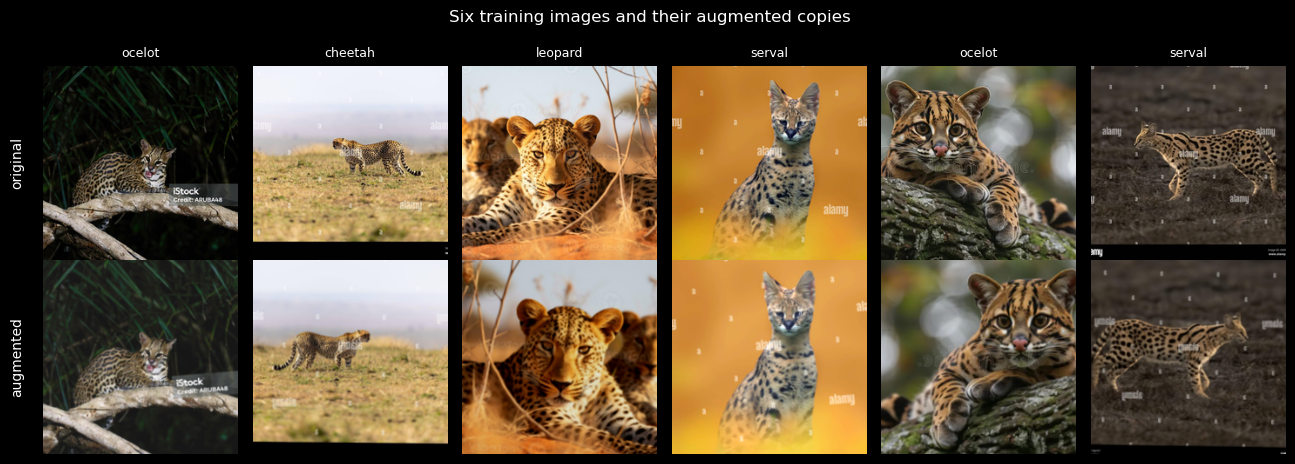

In [6]:
augment = keras.Sequential([
    layers.RandomFlip('horizontal', seed=SEED),
    layers.RandomRotation(8 / 360, fill_mode='reflect', seed=SEED),
    layers.RandomZoom(height_factor=(-0.15, 0.0), fill_mode='reflect', seed=SEED),
    layers.RandomBrightness(0.15, value_range=(0, 255), seed=SEED),
])

BATCH = 64
X_aug = np.empty_like(X_bal)
for i in range(0, len(X_bal), BATCH):
    batch = augment(X_bal[i:i + BATCH].astype('float32'), training=True)
    X_aug[i:i + BATCH] = np.clip(np.asarray(batch), 0, 255).astype(np.uint8)

X_train_final = np.concatenate([X_bal, X_aug])
y_train_final = np.concatenate([y_bal, y_bal])
print(f'training set after balance + augment: {X_train_final.shape}, per class {np.bincount(y_train_final)}')

show = rng.choice(len(X_bal), size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for col, i in enumerate(show):
    axes[0, col].imshow(X_bal[i]); axes[0, col].set_title(CLASSES[y_bal[i]], fontsize=9)
    axes[1, col].imshow(X_aug[i])
    for ax in axes[:, col]:
        ax.axis('off')
axes[0, 0].text(-0.1, 0.5, 'original', transform=axes[0, 0].transAxes, rotation=90, va='center', ha='right')
axes[1, 0].text(-0.1, 0.5, 'augmented', transform=axes[1, 0].transAxes, rotation=90, va='center', ha='right')
plt.suptitle('Six training images and their augmented copies', y=1.0)
plt.tight_layout()
plt.show()

del X_bal, X_aug   # both are inside X_train_final; free the separate copies

The figure shows each transform at work. The cheetah, leopard and right-hand serval are mirrored (along with their watermarks).
The cheetah is also tilted slightly, with a reflected strip filling the edge. The right-hand ocelot is zoomed in, and the
brightness shifts are subtle. Every augmented copy is still a plausible photo of the same animal, which is the point: the
training set gains variety without gaining images that could never occur.

### 3.3 Embed

Each application is loaded with `include_top=False, pooling='avg'` and ImageNet weights, following
`U2-2_CNN-6_TransferLearning` §2–3. Dropping the top removes the 1,000-class ImageNet classifier. Global average pooling then turns the
final feature map into **one embedding vector per image**. Images are fed in batches: each batch is converted to
float, passed through that application's own `preprocess_input`, then through the frozen network. The embedding time
covers both the training and the test set, and is reported in the comparison table.

The same function embeds all three applications. Each one's network is deleted after use, to free memory before the
next one loads.

In [7]:
def embed(key, images, batch_size=32):
    # Embedding vectors from one frozen Keras application, using its own preprocess_input.
    out = []
    for i in range(0, len(images), batch_size):
        x = APPS[key]['preprocess'](images[i:i + batch_size].astype('float32'))
        out.append(np.asarray(APPS[key]['model'].predict(x, verbose=0)))
    return np.concatenate(out)


def embed_application(key):
    app = APPS[key]
    app['model'] = app['build'](include_top=False, weights='imagenet', pooling='avg',
                                input_shape=(224, 224, 3))
    app['params'] = app['model'].count_params()
    start = time.perf_counter()
    app['E_train'] = embed(key, X_train_final)
    app['E_test'] = embed(key, X_test)
    app['embed_time'] = time.perf_counter() - start
    del app['model']
    keras.backend.clear_session()
    gc.collect()
    print(f"{app['title']}: {app['params']:,} params | embeddings train {app['E_train'].shape}, "
          f"test {app['E_test'].shape} | {app['embed_time']:.0f} s")

#### 3.3.1 MobileNetV2

The smallest application: 3.5 M parameters and 1,280-dimensional embeddings.

In [8]:
embed_application('mobilenetv2')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

MobileNetV2: 2,257,984 params | embeddings train (2990, 1280), test (355, 1280) | 95 s


#### 3.3.2 ResNet50

The medium application: 25.6 M parameters and the longest embeddings, at 2,048 dimensions.

In [9]:
embed_application('resnet50')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
ResNet50: 23,587,712 params | embeddings train (2990, 2048), test (355, 2048) | 214 s


#### 3.3.3 EfficientNetV2M

The large application: 54.4 M parameters and 1,280-dimensional embeddings. The slowest to embed by far, especially on a CPU.

In [10]:
embed_application('effnetv2m')

214201816/214201816 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
EfficientNetV2M: 53,150,388 params | embeddings train (2990, 1280), test (355, 1280) | 482 s


**Embedding cost grows with size.** On this machine's CPU, embedding the 3,345 images took 95 s for MobileNetV2,
214 s for ResNet50 and 482 s for EfficientNetV2M, so about 5 times as long from the smallest to the largest. The weight download
on first use happens before the timer starts and is not counted. The TensorFlow deprecation warning printed during the first
embedding comes from Keras's own `clear_session` and does not affect the results.

## 4. Linear probes

Each probe is a `Sequential` with **one Dense output layer**: five units, one per class, with softmax activation. It takes
an application's embedding vectors as input. This is `U2-2_CNN-6_TransferLearning` §4.1's classifier with its two extra layers
left out. A model this simple is a *linear probe*: it can only draw straight boundaries in embedding space, so its
accuracy measures how well the application's embeddings already separate the classes.

**Identical settings for every probe.** The only thing that changes is the input length, which matches each application's
embedding (1,280, 2,048 or 1,280):

| Setting | Value | Why |
|---|---|---|
| Optimizer | Adam, learning rate 0.001 | The standard default. Works well on a convex problem like softmax regression |
| Loss | sparse categorical cross-entropy | Integer labels, one class per image |
| Batch size | 32 | Small enough for frequent updates on about 3,000 training vectors |
| Epochs | 50, fixed | A single linear layer converges quickly. A fixed count rather than early stopping keeps the training identical for all three, and avoids holding out a validation set whose augmented copies would leak from the training set |
| Seed | 42, reset before each probe | Same initial weights and shuffling order for every probe |

The training curves are plotted rather than printed epoch by epoch, which keeps the output short and still shows whether
each probe converged.

In [11]:
PROBE_EPOCHS = 50
PROBE_BATCH = 32
PROBE_LR = 1e-3


def train_probe(key):
    app = APPS[key]
    keras.utils.set_random_seed(SEED)
    probe = keras.Sequential([
        keras.Input(shape=(app['E_train'].shape[1],)),
        layers.Dense(N_CLASSES, activation='softmax'),
    ], name=f'probe_{key}')
    probe.compile(optimizer=keras.optimizers.Adam(learning_rate=PROBE_LR),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.perf_counter()
    history = probe.fit(app['E_train'], y_train_final, epochs=PROBE_EPOCHS, batch_size=PROBE_BATCH,
                        shuffle=True, verbose=0)
    app['train_time'] = time.perf_counter() - start
    app['probe'], app['history'] = probe, history.history
    app['probe_params'] = probe.count_params()
    print(f"{app['title']} probe: {app['probe_params']:,} params | trained in {app['train_time']:.1f} s | "
          f"final training loss {history.history['loss'][-1]:.3f}, accuracy {history.history['accuracy'][-1]:.3f}")

### 4.1 MobileNetV2 probe

In [12]:
train_probe('mobilenetv2')

MobileNetV2 probe: 6,405 params | trained in 17.8 s | final training loss 0.006, accuracy 1.000


### 4.2 ResNet50 probe

In [13]:
train_probe('resnet50')

ResNet50 probe: 10,245 params | trained in 16.5 s | final training loss 0.001, accuracy 1.000


### 4.3 EfficientNetV2M probe

In [14]:
train_probe('effnetv2m')

EfficientNetV2M probe: 6,405 params | trained in 17.0 s | final training loss 0.034, accuracy 0.993


### 4.4 Training curves

All three probes on one set of axes. A curve that is still falling steeply at epoch 50 would mean the probe stopped
too early. A flat curve means it converged.

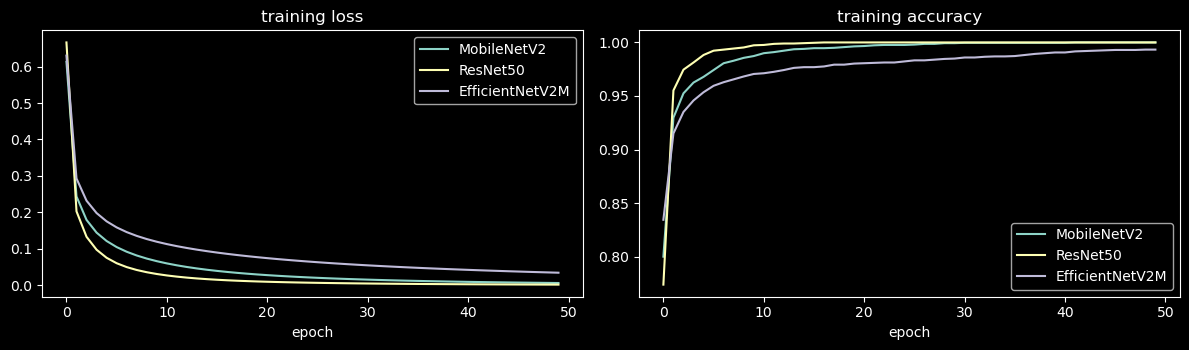

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for key, app in APPS.items():
    axes[0].plot(app['history']['loss'], label=app['title'])
    axes[1].plot(app['history']['accuracy'], label=app['title'])
axes[0].set_title('training loss'); axes[1].set_title('training accuracy')
for ax in axes:
    ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout()
plt.show()

**All three probes converged.** Training loss is close to flat by epoch 30. MobileNetV2 and ResNet50 reach 100% training
accuracy, and EfficientNetV2M reaches 99.3%, with its loss still falling slowly. Training accuracy is about 5 points
above the test accuracies below, so the probes fit the training set, augmented copies included, almost perfectly. More
epochs would only fit it harder, so 50 is enough.

## 5. Evaluation

Every application is evaluated the same way on the **untouched** test set (355 images, natural class distribution):

- **Accuracy**, and **macro-F1**, the unweighted mean of the per-class F1 scores, so every class counts equally
- A full **classification report** (precision, recall and F1 per class)
- A **confusion matrix** with class names on the axes
- **Per-class recall**: the share of each class's test images the model got right. An average can hide one class the
  model has given up on

The same function is used for all three, and it also reports which pair of classes is confused most (counting both
directions), for comparison with Notebook 1's prediction of `leopard` ↔ `jaguar`.

In [16]:
def evaluate(key):
    app = APPS[key]
    y_pred = np.argmax(app['probe'].predict(app['E_test'], verbose=0), axis=1)
    app['y_pred'] = y_pred
    app['accuracy'] = accuracy_score(y_test, y_pred)
    app['macro_f1'] = f1_score(y_test, y_pred, average='macro')
    app['recall'] = recall_score(y_test, y_pred, average=None)
    cm = confusion_matrix(y_test, y_pred, labels=range(N_CLASSES))

    both_ways = cm + cm.T
    np.fill_diagonal(both_ways, 0)
    a, b = np.unravel_index(both_ways.argmax(), both_ways.shape)
    app['most_confused'] = (CLASSES[a], CLASSES[b], int(both_ways[a, b]))

    print(f"{app['title']}: accuracy {app['accuracy']:.3f} | macro-F1 {app['macro_f1']:.3f} | "
          f"most confused: {CLASSES[a]} <-> {CLASSES[b]} ({both_ways[a, b]} test images)\n")
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{app['title']} — test confusion matrix")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    return pd.Series(app['recall'], index=CLASSES, name='recall').round(3).to_frame().T

### 5.1 MobileNetV2

MobileNetV2: accuracy 0.944 | macro-F1 0.944 | most confused: jaguar <-> leopard (9 test images)

              precision    recall  f1-score   support

     cheetah      0.986     0.933     0.959        75
      jaguar      0.915     0.929     0.922        70
     leopard      0.867     0.929     0.897        70
      ocelot      0.972     0.986     0.979        70
      serval      0.985     0.943     0.964        70

    accuracy                          0.944       355
   macro avg      0.945     0.944     0.944       355
weighted avg      0.946     0.944     0.944       355



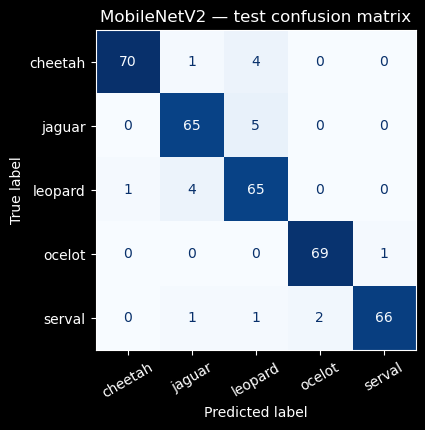

,cheetah,jaguar,leopard,ocelot,serval
recall,0.933,0.929,0.929,0.986,0.943


In [17]:
evaluate('mobilenetv2')

**MobileNetV2: 94.4% accuracy, 20 errors out of 355.** Nine of the errors are between `jaguar` and `leopard` (5 jaguars called
leopard, 4 leopards called jaguar). The next most common error is 4 cheetahs called leopard. `ocelot` is nearly perfect, at 69 of 70.

### 5.2 ResNet50

ResNet50: accuracy 0.949 | macro-F1 0.950 | most confused: jaguar <-> leopard (8 test images)

              precision    recall  f1-score   support

     cheetah      0.986     0.933     0.959        75
      jaguar      0.917     0.943     0.930        70
     leopard      0.890     0.929     0.909        70
      ocelot      0.958     0.986     0.972        70
      serval      1.000     0.957     0.978        70

    accuracy                          0.949       355
   macro avg      0.950     0.950     0.950       355
weighted avg      0.951     0.949     0.950       355



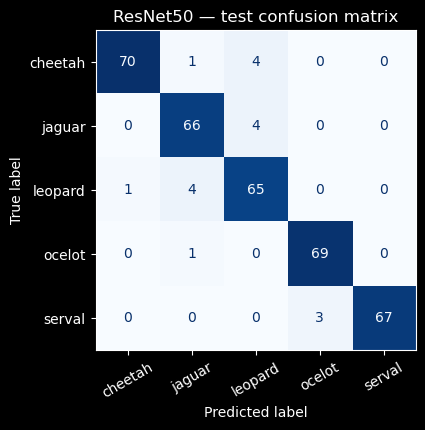

,cheetah,jaguar,leopard,ocelot,serval
recall,0.933,0.943,0.929,0.986,0.957


In [18]:
evaluate('resnet50')

**ResNet50: 94.9% accuracy, 18 errors.** The pattern is the same: 8 `jaguar` ↔ `leopard` errors and 4 cheetahs called
leopard. Its only other repeated error is 3 servals called ocelot. Every image it labelled `serval` really was one (precision 1.000).

### 5.3 EfficientNetV2M

EfficientNetV2M: accuracy 0.949 | macro-F1 0.949 | most confused: jaguar <-> leopard (6 test images)

              precision    recall  f1-score   support

     cheetah      0.972     0.933     0.952        75
      jaguar      0.944     0.957     0.950        70
     leopard      0.915     0.929     0.922        70
      ocelot      0.958     0.971     0.965        70
      serval      0.957     0.957     0.957        70

    accuracy                          0.949       355
   macro avg      0.949     0.950     0.949       355
weighted avg      0.950     0.949     0.949       355



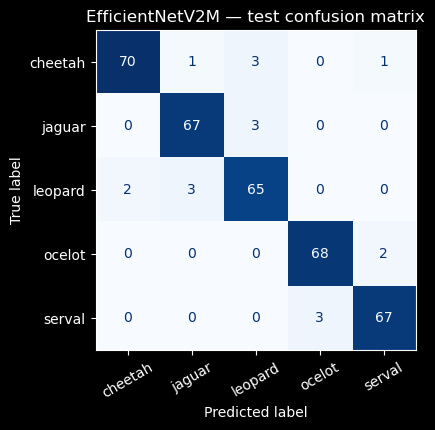

,cheetah,jaguar,leopard,ocelot,serval
recall,0.933,0.957,0.929,0.971,0.957


In [19]:
evaluate('effnetv2m')

**EfficientNetV2M: 94.9% accuracy, 18 errors.** It matches ResNet50 overall, but its errors are distributed differently.
`jaguar` ↔ `leopard` drops to 6, and its jaguar recall is the highest of the three (0.957). On the other hand, it confuses the two small cats
more: 5 `serval` ↔ `ocelot` errors, against 3 for each of the other two models.

## 6. Comparison

One row per application. **Params** counts the frozen Keras application only. **Embed time** covers the training and test sets
together (both the same size for every application). **Probe params** and **train time** cover the linear probe
alone.

In [20]:
summary = pd.DataFrame([{
    'application': app['title'],
    'params_M': app['params'] / 1e6,
    'embed_time_s': app['embed_time'],
    'probe_params': app['probe_params'],
    'probe_train_time_s': app['train_time'],
    'test_accuracy': app['accuracy'],
    'macro_f1': app['macro_f1'],
} for app in APPS.values()]).set_index('application').round({'params_M': 1, 'embed_time_s': 0,
                                                              'probe_train_time_s': 1, 'test_accuracy': 3,
                                                              'macro_f1': 3})
recall_table = pd.DataFrame({app['title']: app['recall'] for app in APPS.values()}, index=CLASSES).round(3)
confused = pd.DataFrame({app['title']: {'pair': f"{app['most_confused'][0]} <-> {app['most_confused'][1]}",
                                        'test images': app['most_confused'][2]} for app in APPS.values()}).T
display(summary)
display(recall_table.rename_axis('per-class recall'))
confused.rename_axis('most confused pair')

,params_M,embed_time_s,probe_params,probe_train_time_s,test_accuracy,macro_f1
application,,,,,,
MobileNetV2,2.3,95.0,6405,17.8,0.944,0.944
ResNet50,23.6,214.0,10245,16.5,0.949,0.950
EfficientNetV2M,53.2,482.0,6405,17.0,0.949,0.949


,MobileNetV2,ResNet50,EfficientNetV2M
per-class recall,,,
cheetah,0.933,0.933,0.933
jaguar,0.929,0.943,0.957
leopard,0.929,0.929,0.929
ocelot,0.986,0.986,0.971
serval,0.943,0.957,0.957


,pair,test images
most confused pair,,
MobileNetV2,jaguar <-> leopard,9
ResNet50,jaguar <-> leopard,8
EfficientNetV2M,jaguar <-> leopard,6


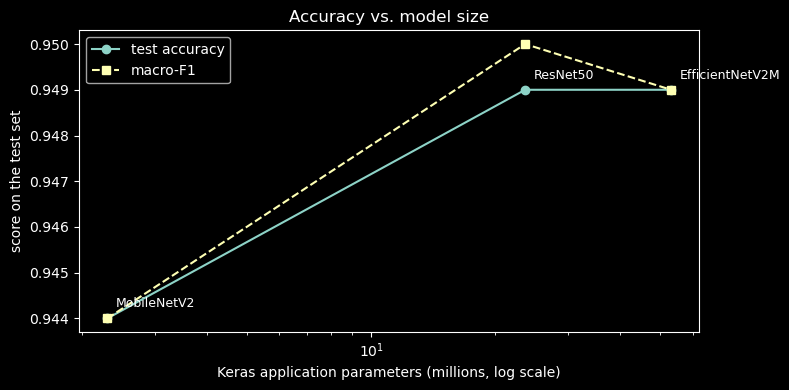

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(summary['params_M'], summary['test_accuracy'], 'o-', label='test accuracy')
ax.plot(summary['params_M'], summary['macro_f1'], 's--', label='macro-F1')
for name, r in summary.iterrows():
    ax.annotate(name, (r['params_M'], r['test_accuracy']), textcoords='offset points', xytext=(6, 8), fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('Keras application parameters (millions, log scale)')
ax.set_ylabel('score on the test set')
ax.set_title('Accuracy vs. model size')
ax.legend()
plt.tight_layout()
plt.show()

### 6.1 Discussion

**Does bigger win? Barely, and not measurably.** Test accuracy goes 94.4% → 94.9% → 94.9% and macro-F1 0.944 → 0.950 →
0.949, across a 23-fold increase in parameters (2.3 M to 53.2 M). The gap between the smallest and the largest application is **two
test images out of 355**. With 355 test images, an accuracy near 95% carries a standard error of about ±1.2 points, so the three
cannot be told apart.

**Where do the returns flatten? Immediately.** The accuracy-vs-size curve is already flat at MobileNetV2: ResNet50 adds 0.5 points
and EfficientNetV2M adds nothing more. Size does show in one place, the hardest pair. `jaguar` ↔ `leopard` errors fall from 9 to 8 to
6, and jaguar recall rises from 0.929 to 0.943 to 0.957. The larger networks' richer features go where the distinction is
finest, rosettes with and without a centre dot. But EfficientNetV2M gives that gain back on `serval` ↔ `ocelot` (3 → 3 → 5).

**Was the largest application worth its embedding time? Not on this dataset.** EfficientNetV2M took 482 s to embed, against 95 s
for MobileNetV2, so 5 times the compute, and in the Streamlit app every upload would wait about as much longer, all for the same accuracy as
ResNet50. One caveat counts in its favour: it ran at 224×224, well below its native 480×480, so it was working with less detail
than it was designed for. At full resolution it might pull ahead, at roughly four times the pixels and more compute again. On a
dataset this size, the bottleneck is not the backbone. The pretrained features are already good enough: ImageNet includes
leopard, jaguar and cheetah, and its spotted-texture features carry over to the other two cats. What limits a linear probe here is about
1,400 distinct training images and the genuinely hard test images: distant cats, partial views, and rosettes too small to resolve. For
this task MobileNetV2 gives the best accuracy per second, and ResNet50 is a safe middle choice.

**Notebook 1's predictions, revisited:**

| Prediction | Result |
|---|---|
| `leopard` ↔ `jaguar` is the most-confused pair | **Confirmed** for all three applications (9, 8 and 6 errors) |
| `serval` ↔ `cheetah` is the runner-up | **Wrong.** At most 1 error between them across all three. The serval's ears and build separate it from the cheetah reliably. The real runners-up are `serval` ↔ `ocelot` (3–5 errors) and cheetahs called leopard (3–4) |
| `cheetah` is the easiest big cat | **Wrong.** Cheetah recall is 0.933 for all three, second lowest, because 3–4 cheetahs are called leopard each time: solid spots read as rosettes when they are small or blurred |
| `ocelot` and `serval`, the two non-ImageNet classes, have the lowest recall | **Wrong, and the most interesting result.** `ocelot` has the *highest* recall (0.971–0.986) and `serval` is 0.943–0.957. The lowest is `leopard` (0.929 for all three), an ImageNet class. ImageNet embeddings separate species they were never trained to name |

**Is ~95% suspicious?** The prompt warns that accuracy at or near 100% usually means leakage or a shortcut. 95% is not that.
Duplicates, including cross-class ones, were removed before the split in Notebook 2, and the errors fall on the visually hardest pairs
rather than at random. That is the pattern a model reading coat patterns would produce. It does not rule out the models *also* using
the habitat colours Notebook 2 found in the mean images. Notebook 4 tests that directly.

## 7. Export

Each trained probe is saved to the repo's `models/` folder as `P2_N3_<application>.keras`. The application name in the
filename is how Notebook 4 and the app know which Keras application to rebuild and join to each probe. The probes are
tiny (a few thousand parameters each), so they fit easily in the repo without Git LFS. The frozen applications are
**not** saved: Notebook 4 and the app rebuild them from `keras.applications` with the same arguments used here
(`include_top=False, weights='imagenet', pooling='avg', input_shape=(224, 224, 3)`).

The label→index mapping is saved next to the probes, so Notebook 4 and the app read class names from the same file.

In [22]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
for key, app in APPS.items():
    path = MODELS_DIR / f'P2_N3_{key}.keras'
    app['probe'].save(path)
    print(f'{path.name:<24} {path.stat().st_size / 1024:6.1f} KB')

(MODELS_DIR / 'label_map.json').write_text(json.dumps(label_map, indent=2))
print(f'label_map.json           {label_map}')

reloaded = keras.models.load_model(MODELS_DIR / 'P2_N3_mobilenetv2.keras')
assert np.allclose(reloaded.predict(APPS['mobilenetv2']['E_test'][:8], verbose=0),
                   APPS['mobilenetv2']['probe'].predict(APPS['mobilenetv2']['E_test'][:8], verbose=0), atol=1e-5)
print('Reload check passed: a saved probe gives the same predictions as the trained one.')

P2_N3_mobilenetv2.keras    90.7 KB
P2_N3_resnet50.keras      135.7 KB
P2_N3_effnetv2m.keras      90.7 KB
label_map.json           {'cheetah': 0, 'jaguar': 1, 'leopard': 2, 'ocelot': 3, 'serval': 4}
Reload check passed: a saved probe gives the same predictions as the trained one.
